In [1]:
# =============================================
# ПРАКТИЧЕСКАЯ РАБОТА №11 (ПРОДВИНУТЫЙ УРОВЕНЬ)
# Логистическая регрессия - Предсказание выживания на Титанике
# =============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, 
                             roc_auc_score, roc_curve, accuracy_score)
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8')

# ====================== 1. ЗАГРУЗКА ДАННЫХ ======================
df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')

print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nПропуски:")
print(df.isnull().sum())

Размер датасета: (891, 12)

Первые 5 строк:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Пропуски:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


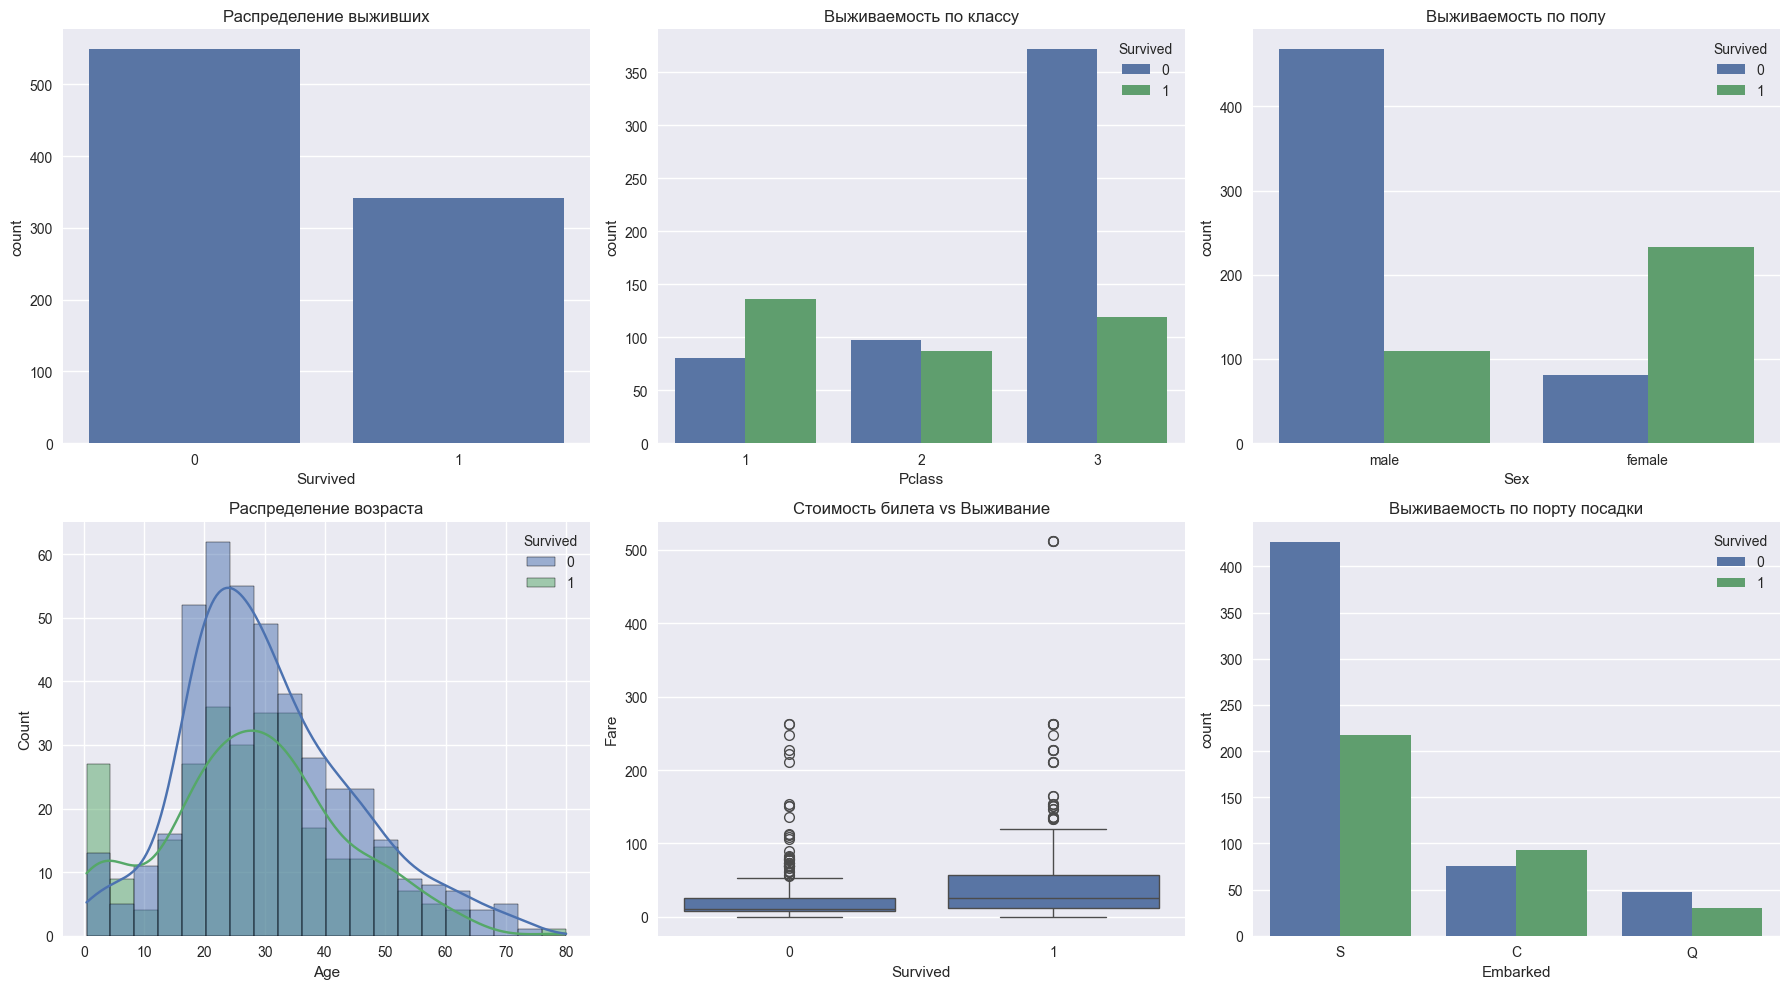

In [2]:
# ====================== 2. РАСШИРЕННЫЙ EDA ======================
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.countplot(data=df, x='Survived', ax=axes[0,0])
axes[0,0].set_title('Распределение выживших')

sns.countplot(data=df, x='Pclass', hue='Survived', ax=axes[0,1])
axes[0,1].set_title('Выживаемость по классу')

sns.countplot(data=df, x='Sex', hue='Survived', ax=axes[0,2])
axes[0,2].set_title('Выживаемость по полу')

sns.histplot(data=df, x='Age', hue='Survived', kde=True, ax=axes[1,0])
axes[1,0].set_title('Распределение возраста')

sns.boxplot(data=df, x='Survived', y='Fare', ax=axes[1,1])
axes[1,1].set_title('Стоимость билета vs Выживание')

sns.countplot(data=df, x='Embarked', hue='Survived', ax=axes[1,2])
axes[1,2].set_title('Выживаемость по порту посадки')

plt.tight_layout()
plt.show()

In [3]:
# ====================== 3. ПРЕДОБРАБОТКА ДАННЫХ ======================
# Создаём новые признаки
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)
df['Title'] = df['Title'].replace(['Lady', 'Countess','Capt', 'Col','Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
df['Title'] = df['Title'].replace(['Mlle','Ms'], 'Miss')
df['Title'] = df['Title'].replace(['Mme'], 'Mrs')

# Заполнение пропусков
df['Age'] = df.groupby(['Title', 'Pclass'])['Age'].transform(lambda x: x.fillna(x.median()))
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Fare'] = df['Fare'].fillna(df['Fare'].median())

# Создаём дополнительные признаки
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)

# Выбираем признаки
features = ['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'Title', 'IsAlone']
X = df[features]
y = df['Survived']

# Предобработка через ColumnTransformer
numeric_features = ['Age', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked', 'Title', 'IsAlone']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False), categorical_features)
    ])

In [4]:
# ====================== 4. МОДЕЛЬ + GridSearchCV ======================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

# Подбор гиперпараметров
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear']
}

grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print("Лучший ROC-AUC на кросс-валидации:", grid_search.best_score_)

best_model = grid_search.best_estimator_

Лучшие параметры: {'classifier__C': 100, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Лучший ROC-AUC на кросс-валидации: 0.8606001762663205


In [5]:
# ====================== 5. ОЦЕНКА МОДЕЛИ ======================
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("=== Classification Report ===")
print(classification_report(y_test, y_pred))

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.82      0.87      0.85       110
           1       0.77      0.70      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179

Accuracy: 0.8045
ROC-AUC: 0.8615


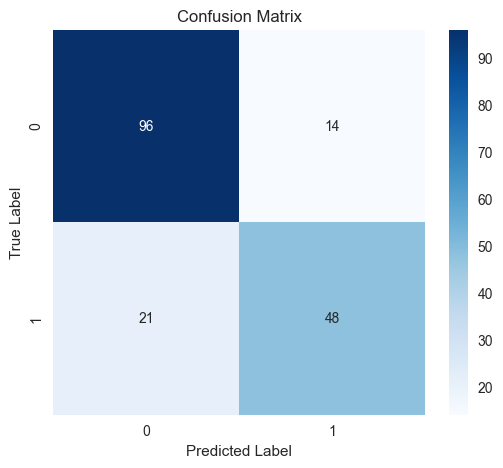

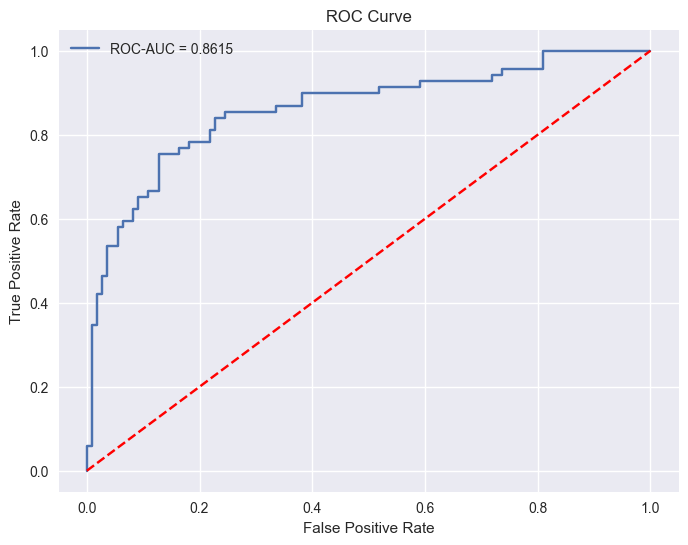

In [6]:
# ====================== 6. ВИЗУАЛИЗАЦИЯ ======================
# Confusion Matrix
plt.figure(figsize=(6,5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc_score(y_test, y_prob):.4f}')
plt.plot([0,1],[0,1],'r--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()